**Step 1: Import libraries**

In [1]:
# data handling
import pandas as pd
import numpy as np

# data visualization
import matplotlib.pyplot as plt
import seaborn as sns

#spliting
from sklearn.model_selection import train_test_split

# preprocessing
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder

# deep learning core
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model # Required instead of Sequential for multi-output networks
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, ReLU
from tensorflow.keras.callbacks import EarlyStopping, LearningRateScheduler

# model evaluation
from sklearn.metrics import classification_report   
from sklearn.metrics import confusion_matrix 
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score


**Step 2: Load Dataset**

In [2]:
df = pd.read_csv("../data/employee_clean.csv")

**Step 3: Features & targets**

In [3]:
X = df.drop(columns=['EmployeeNumber','Attrition','MonthlyIncome'])
y = df['MonthlyIncome']

**Step 4: Train test split**

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

**Step 5: Preprocessing pipeline**

In [5]:
cat_cols = ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']
num_cols = numerical_features = [
    'Age', 'DailyRate', 'DistanceFromHome', 'Education', 'HourlyRate', 
    'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'EnvironmentSatisfaction',
    'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 
    'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 
    'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 
    'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager'
]

num_transformer = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("scr", StandardScaler())
])

cat_transformer = Pipeline([
    ("imp", SimpleImputer(strategy="most_frequent")),

    # 'sparse_output=False' --> ensures it returns a normal numpy array instead of a matrix
    # 'drop='first'' --> removes one column per feature to prevent the dummy variable trap
    ('cat', OneHotEncoder(sparse_output=False, drop='first'))
])


preprocessor = ColumnTransformer([
    ("num_processing", num_transformer, num_cols),
    ("cat_processing", cat_transformer, cat_cols)
], remainder='passthrough' 
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

**Step 6: Build ANN**

In [17]:
model = Sequential([
    Input(shape=(X_train_processed.shape[1],)),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(16, activation='relu'),
    Dense(1)
])

**Step 7: Compile**

In [18]:
model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

**Step 8: model summary**

In [19]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │         2,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,441 (21.25 KB)

 Trainable params: 5,441 (21.25 KB)

 Non-trainable params: 0 (0.00 B)

**Step 9: Train**

In [20]:
history = model.fit(
    X_train_processed,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    #callbacks=EarlyStopping()
)

Epoch 1/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 62327012.0000 - mae: 6381.2563 - val_loss: 64962084.0000 - val_mae: 6375.8379
Epoch 2/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 62213772.0000 - mae: 6373.2949 - val_loss: 64741492.0000 - val_mae: 6360.7485
Epoch 3/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 61769664.0000 - mae: 6342.9561 - val_loss: 63880980.0000 - val_mae: 6304.6006
Epoch 4/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 60120200.0000 - mae: 6238.7021 - val_loss: 61176684.0000 - val_mae: 6132.9375
Epoch 5/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 55695972.0000 - mae: 5960.5449 - val_loss: 54845588.0000 - val_mae: 5720.9980
Epoch 6/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 46824008.0000 - mae: 5354.9888 - val_loss: 43221256.0000 - val_mae: 4894.0376
Epoch 7/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 33211666.0000 - mae: 4277.6211 - val_loss: 28243820.0000 - val_mae: 3704.4802
Epoch 8/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s

**Step 10: Predict**

In [21]:
pred = model.predict(X_test_processed)

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


**Step 11: Evauate**

In [22]:
print("MAE :", mean_absolute_error(y_test, pred))

print("RMSE :", np.sqrt(mean_squared_error(y_test, pred)))

print("R2 :", round(r2_score(y_test, pred)*100,2),'%')

MAE : 936.8235473632812
RMSE : 1233.939727053149
R2 : 93.03 %


**Step 12. Classification report**

Regression doesn't have classes, so there's no classification report.

**Step 13: Confusion Matrix**

Confusion matrices are only for classification.

**Step 14: Training Curve**

Regression tracks loss (and optionally MAE), not accuracy.

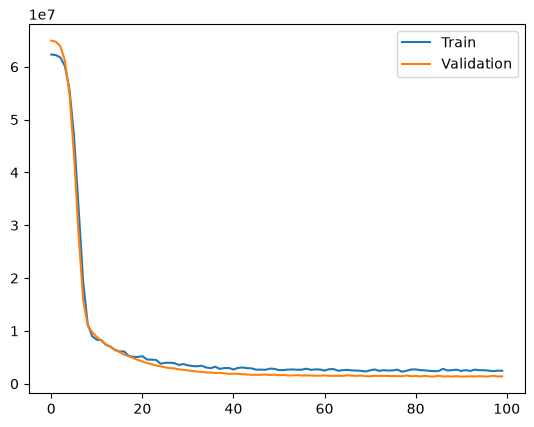

In [23]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.legend(['Train','Validation'])
plt.show()

**Step 15: Save Model**

In [24]:
model.save("../models/monthlyIncome_model.keras")
print("Model Saved successfully...!")

Model Saved successfully...!
